In [1]:
#Imports

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")

pd.set_option("display.max_columns", None)

In [2]:
#Load Dataset

df = pd.read_csv(
    "/Users/srinidhinunna/Desktop/HighQ/data/PS_20174392719_1491204439457_log.csv"
)

print("Dataset Loaded")
print("Shape:", df.shape)

Dataset Loaded
Shape: (6362620, 11)


In [3]:
#Dataset Overview

print("Rows:", len(df))
print("Columns:", len(df.columns))

print("\nFraud counts:")
print(df["isFraud"].value_counts())

print("\nFraud Rate (%):")
print(round(df["isFraud"].mean() * 100, 4))

Rows: 6362620
Columns: 11

Fraud counts:
isFraud
0    6354407
1       8213
Name: count, dtype: int64

Fraud Rate (%):
0.1291


In [4]:
#Dataset Structure

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 534.0 MB


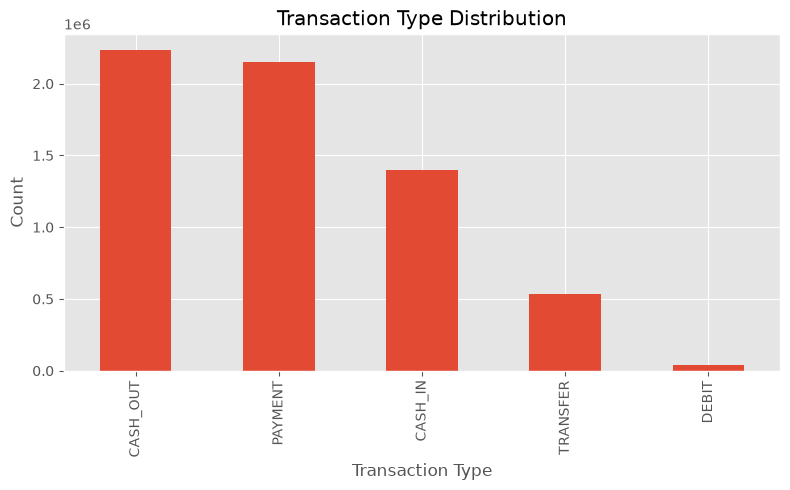

In [5]:
#Transaction Type Distribution

plt.figure(figsize=(8,5))

df["type"].value_counts().plot(
    kind="bar"
)

plt.title("Transaction Type Distribution")
plt.xlabel("Transaction Type")
plt.ylabel("Count")

plt.tight_layout()

plt.show()

In [6]:
#Fraud by Transaction Type

pd.crosstab(
    df["type"],
    df["isFraud"]
)

isFraud,0,1
type,,
CASH_IN,1399284,0
CASH_OUT,2233384,4116
DEBIT,41432,0
PAYMENT,2151495,0
TRANSFER,528812,4097


type
TRANSFER    0.768799
CASH_OUT    0.183955
CASH_IN     0.000000
DEBIT       0.000000
PAYMENT     0.000000
Name: isFraud, dtype: float64


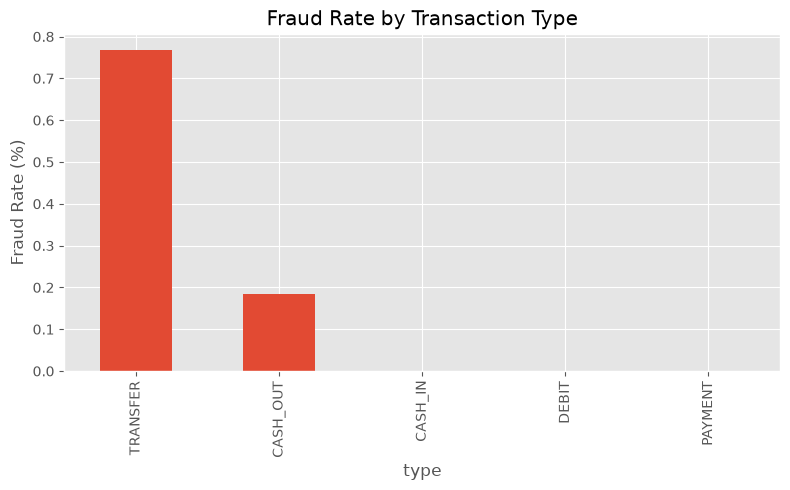

In [7]:
#Fraud Rate by Transaction Type

fraud_rate = (
    df.groupby("type")["isFraud"]
    .mean()
    .sort_values(ascending=False)
)

print(fraud_rate * 100)

plt.figure(figsize=(8,5))

(fraud_rate * 100).plot(
    kind="bar"
)

plt.ylabel("Fraud Rate (%)")
plt.title("Fraud Rate by Transaction Type")

plt.tight_layout()

plt.show()

In [8]:
#Focus Only On High Risk Transactions

fraud_df = df[
    df["type"].isin(
        ["TRANSFER", "CASH_OUT"]
    )
].copy()

print(fraud_df.shape)

print(fraud_df["isFraud"].value_counts())

(2770409, 11)
isFraud
0    2762196
1       8213
Name: count, dtype: int64


In [9]:
#Fraud Percentage In High-Risk Transactions

fraud_percentage = (
    fraud_df["isFraud"].mean()
    * 100
)

print(
    f"Fraud Rate In High-Risk Transactions: {fraud_percentage:.4f}%"
)

Fraud Rate In High-Risk Transactions: 0.2965%


In [10]:
#Amount Statistics

fraud_df.groupby(
    "isFraud"
)["amount"].describe()

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,2762196.0,3.141155e+05,8.771441e+05,0.01,82908.2325,171034.46,305994.185,92445516.64
1,8213.0,1.467967e+06,2.404253e+06,0.00,127091.3300,441423.44,1517771.480,10000000.00


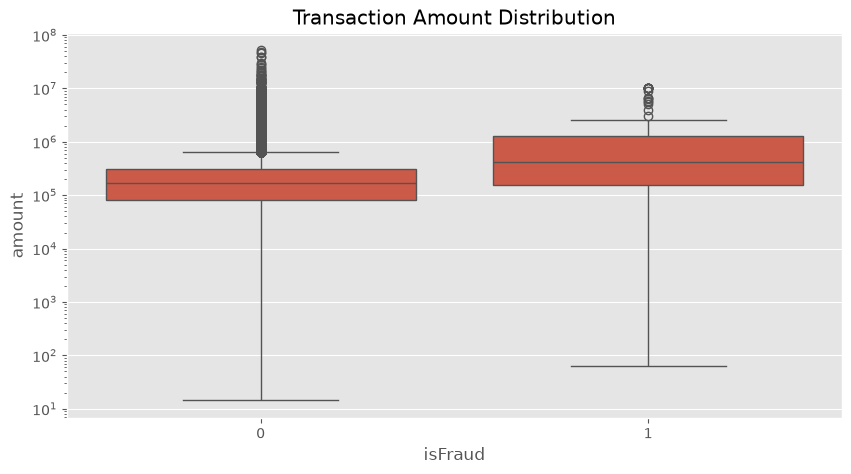

In [11]:
#Fraud vs Non Fraud Amounts

sample = fraud_df.sample(
    50000,
    random_state=42
)

plt.figure(figsize=(10,5))

sns.boxplot(
    data=sample,
    x="isFraud",
    y="amount"
)

plt.yscale("log")

plt.title(
    "Transaction Amount Distribution"
)

plt.show()

In [12]:
#Rule-Based Fraud Detection Analysis

pd.crosstab(
    df["isFlaggedFraud"],
    df["isFraud"]
)

isFraud,0,1
isFlaggedFraud,,
0,6354407,8197
1,0,16


In [13]:
#Feature Engineering

fraud_df["balance_error_orig"] = (
    fraud_df["oldbalanceOrg"]
    - fraud_df["amount"]
    - fraud_df["newbalanceOrig"]
)

fraud_df["balance_error_dest"] = (
    fraud_df["oldbalanceDest"]
    + fraud_df["amount"]
    - fraud_df["newbalanceDest"]
)

fraud_df["amount_ratio"] = (
    fraud_df["amount"]
    /
    (fraud_df["oldbalanceOrg"] + 1)
)

fraud_df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,balance_error_orig,balance_error_dest,amount_ratio
2,1,TRANSFER,181.00,C1305486145,181.0,0.0,C553264065,0.0,0.00,1,0,0.00,181.0,0.994505
3,1,CASH_OUT,181.00,C840083671,181.0,0.0,C38997010,21182.0,0.00,1,0,0.00,21363.0,0.994505
15,1,CASH_OUT,229133.94,C905080434,15325.0,0.0,C476402209,5083.0,51513.44,0,0,-213808.94,182703.5,14.950668
19,1,TRANSFER,215310.30,C1670993182,705.0,0.0,C1100439041,22425.0,0.00,0,0,-214605.30,237735.3,304.972096
24,1,TRANSFER,311685.89,C1984094095,10835.0,0.0,C932583850,6267.0,2719172.89,0,0,-300850.89,-2401220.0,28.763925


In [14]:
#Encode Transaction Type

fraud_df["type"] = fraud_df["type"].map(
    {
        "TRANSFER":0,
        "CASH_OUT":1
    }
)

fraud_df["type"].value_counts()

type
1    2237500
0     532909
Name: count, dtype: int64

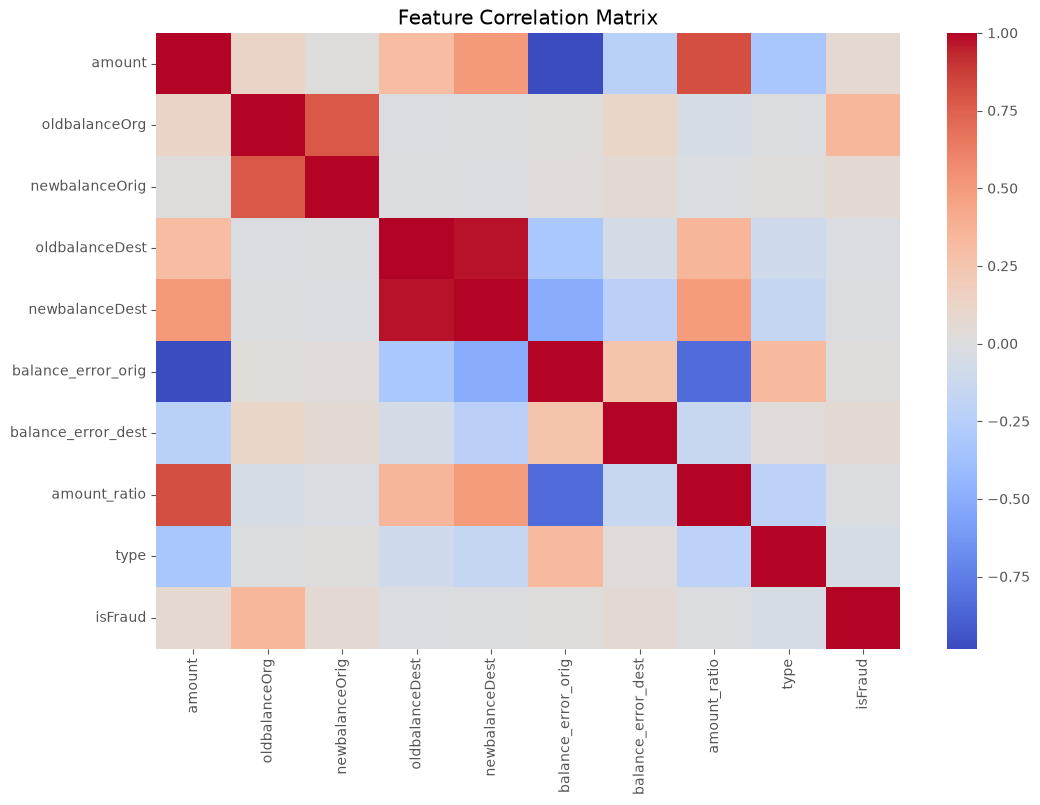

In [15]:
#Correlation Heatmap

features = [
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "balance_error_orig",
    "balance_error_dest",
    "amount_ratio",
    "type",
    "isFraud"
]

plt.figure(figsize=(12,8))

corr = (
    fraud_df[features]
    .corr()
)

sns.heatmap(
    corr,
    cmap="coolwarm"
)

plt.title(
    "Feature Correlation Matrix"
)

plt.show()

In [16]:
#Create Balanced Dataset

fraud = fraud_df[
    fraud_df["isFraud"] == 1
]

nonfraud = fraud_df[
    fraud_df["isFraud"] == 0
].sample(
    n=len(fraud),
    random_state=42
)

balanced_df = pd.concat(
    [fraud, nonfraud]
)

balanced_df = balanced_df.sample(
    frac=1,
    random_state=42
)

print(
    balanced_df["isFraud"].value_counts()
)

print(
    balanced_df.shape
)

isFraud
0    8213
1    8213
Name: count, dtype: int64
(16426, 14)


In [17]:
#Save Dataset For Modeling

balanced_df.to_csv(
    "/Users/srinidhinunna/Desktop/HighQ/data/balanced_fraud_dataset.csv",
    index=False
)

print("Saved")

Saved


In [18]:
#Create Small Quantum Dataset

fraud_q = fraud.sample(
    2000,
    random_state=42
)

nonfraud_q = nonfraud.sample(
    2000,
    random_state=42
)

quantum_df = pd.concat(
    [fraud_q, nonfraud_q]
)

quantum_df = quantum_df.sample(
    frac=1,
    random_state=42
)

print(
    quantum_df["isFraud"].value_counts()
)

print(
    quantum_df.shape
)

isFraud
1    2000
0    2000
Name: count, dtype: int64
(4000, 14)


In [19]:
#Save Quantum Dataset

quantum_df.to_csv(
    "/Users/srinidhinunna/Desktop/HighQ/data/quantum_dataset.csv",
    index=False
)

print("Quantum dataset saved")

Quantum dataset saved


# Key Findings

1. Fraud is concentrated in TRANSFER and CASH_OUT transactions.
2. TRANSFER transactions show the highest fraud rate (~0.77%).
3. Fraud represents only a very small fraction of total transactions.
4. Severe class imbalance exists and requires careful evaluation.
5. Engineered balance-based features may provide useful fraud signals.
6. A balanced dataset was created for classical machine learning experiments.
7. A reduced dataset was created for QSVM and quantum kernel experiments.

In [46]:
import pandas as pd

fraud_df = pd.read_csv(
    "/Users/srinidhinunna/Desktop/HighQ/data/balanced_fraud_dataset.csv"
)

fraud = fraud_df[
    fraud_df["isFraud"] == 1
]

nonfraud = fraud_df[
    fraud_df["isFraud"] == 0
]

In [48]:
fraud_q = fraud.sample(
    500,
    random_state=42
)

nonfraud_q = nonfraud.sample(
    500,
    random_state=42
)

quantum_medium = pd.concat(
    [fraud_q, nonfraud_q]
)

quantum_medium = quantum_medium.sample(
    frac=1,
    random_state=42
)

print(quantum_medium.shape)

print(
    quantum_medium["isFraud"]
    .value_counts()
)

(1000, 14)
isFraud
0    500
1    500
Name: count, dtype: int64


In [50]:
quantum_medium.to_csv(
    "/Users/srinidhinunna/Desktop/HighQ/data/quantum_dataset_medium.csv",
    index=False
)

print("Saved")

Saved
